# Laporan Source Code UAS IR Kelompok 4

Mata Kuliah: Temu Kembali Informasi

Dosen Pengampu: Novi  Yusliani, S.Kom., M.T

Anggota Kelompok 4:
1. Nurul Adhaini Nasution (09021282328125)
2. Githa Evelyn (09021282328124)
3. Putri Alimah Azizah (09021282328069)
4. Erlangga Saputra (09021282328100)


# 1. Import Library dan Konfigurasi Awal

Memuat seluruh pustaka Python yang diperlukan dan mengunci nilai SEED = 42 agar pembagian 5-Fold serta proses pelatihan pohon keputusan menghasilkan angka yang konsisten setiap kali dijalankan.

In [1]:
import re
import gc
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import GroupKFold

import lightgbm
from lightgbm import LGBMRanker
from scipy.stats import wilcoxon

import warnings
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

print(f"Library berhasil diimport. LightGBM version: {lightgbm.__version__}")

Library berhasil diimport. LightGBM version: 4.6.0


# 2. Mengalokasikan Path dan Membaca Dataset

Mencari lokasi file metadata.csv, topics-rnd3.csv, dan qrels.csv secara otomatis di direktori input Kaggle, lalu memuatnya ke dalam DataFrame.

In [2]:
DATA_DIR = Path("/kaggle/input/competitions/trec-covid-information-retrieval")

metadata_path = next(DATA_DIR.rglob("metadata.csv"))
topics_path = next(DATA_DIR.rglob("topics-rnd3.csv"))
qrels_path = next(DATA_DIR.rglob("qrels.csv"))

metadata = pd.read_csv(metadata_path)
topics = pd.read_csv(topics_path)
qrels = pd.read_csv(qrels_path)

print("Metadata:", metadata.shape, "| Topics:", topics.shape, "| Qrels:", qrels.shape)

Metadata: (128492, 19) | Topics: (40, 4) | Qrels: (20728, 4)


# 3. Preprocessing, Perluasan Kueri, dan Parameter Eksperimen

Selain membersihkan teks judul dan abstrak, pada tahap ini dibuat kolom baru bernama full_query yang menggabungkan kata kunci singkat (query) dengan kalimat pertanyaan lengkap (question) pada dataset topik.
* 3a. Pembersihan Teks Artikel: Menghapus duplikasi cord_uid, mengubah huruf ke huruf kecil, membuang tag HTML serta tanda baca, lalu menggabungkan judul dan abstrak.

In [3]:
metadata.columns = [c.strip().lower() for c in metadata.columns]
metadata = metadata[["cord_uid", "title", "abstract"]].copy()
metadata["cord_uid"] = metadata["cord_uid"].astype(str).str.strip()
metadata["title"] = metadata["title"].fillna("").astype(str)
metadata["abstract"] = metadata["abstract"].fillna("").astype(str)

metadata = metadata.drop_duplicates(subset="cord_uid")
metadata = metadata[
    (metadata["title"].str.len() > 0) | (metadata["abstract"].str.len() > 0)
].reset_index(drop=True)

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

metadata["title_clean"] = metadata["title"].apply(clean_text)
metadata["abstract_clean"] = metadata["abstract"].apply(clean_text)
metadata["document_text"] = (metadata["title_clean"] + " " + metadata["abstract_clean"]).str.strip()

print("Jumlah metadata bersih:", len(metadata))

Jumlah metadata bersih: 128139


* 3b. Penyelarasan Topics (Full Query) & Qrels: Menggabungkan kolom query dan question menjadi full_query agar informasi pencarian lebih lengkap, menyaring 35 topik valid, dan menetapkan parameter eksperimen.

In [4]:
topics.columns = [c.strip().lower() for c in topics.columns]
topics = topics.rename(columns={"topic-id": "topic_id"})
topics["topic_id"] = pd.to_numeric(topics["topic_id"], errors="coerce")
topics = topics.dropna(subset=["topic_id", "query"]).copy()
topics["topic_id"] = topics["topic_id"].astype(int)
topics["query"] = topics["query"].fillna("").astype(str)
topics["question"] = topics["question"].fillna("").astype(str)

# PENINGKATAN 1: Gabungkan query dan question menjadi full_query
topics["full_query"] = (topics["query"] + " " + topics["question"]).str.strip()

qrels.columns = [c.strip().lower() for c in qrels.columns]
qrels = qrels.rename(columns={"topic-id": "topic_id", "cord-id": "cord_uid", "judgement": "judgment"})
qrels["topic_id"] = pd.to_numeric(qrels["topic_id"], errors="coerce")
qrels["judgment"] = pd.to_numeric(qrels["judgment"], errors="coerce")
qrels["cord_uid"] = qrels["cord_uid"].astype(str).str.strip()
qrels = qrels.dropna(subset=["topic_id", "judgment", "cord_uid"]).copy()
qrels["topic_id"] = qrels["topic_id"].astype(int)
qrels["judgment"] = qrels["judgment"].astype(int)
qrels = qrels.groupby(["topic_id", "cord_uid"], as_index=False)["judgment"].max()

valid_topic_ids = sorted(set(topics["topic_id"]) & set(qrels["topic_id"]))
topics = topics[topics["topic_id"].isin(valid_topic_ids)].sort_values("topic_id").reset_index(drop=True)

# Parameter Eksperimen
TOP_K = 1000
RERANK_DEPTH = 100
PASSAGE_LENGTH = 40
PASSAGE_OVERLAP = 10
MAX_PASSAGES = 20
N_SPLITS = 5
K1 = 1.5
B = 0.75

print("Jumlah topik valid:", len(topics))
print("Contoh full_query topik 1:", topics.loc[0, "full_query"])

Jumlah topik valid: 35
Contoh full_query topik 1: coronavirus origin what is the origin of COVID-19


# 4. Pembagunan Indeks & Candidate Retrieval BM25

Membangun indeks matriks jarang (CSC Sparse Matrix) dari seluruh artikel, lalu mencari 1.000 kandidat terbaik per topik menggunakan full_query. Perhatikan peningkatan nilai Candidate Recall@1000 dibandingkan sebelumnya karena kata kunci dari kolom question kini ikut dicari.

In [5]:
start_time = time.time()

vectorizer = CountVectorizer(
    stop_words="english",
    min_df=2,
    max_features=100000,
    dtype=np.int32
)

X = vectorizer.fit_transform(metadata["document_text"])
X_csc = X.tocsc()
vocabulary = vectorizer.vocabulary_
analyzer = vectorizer.build_analyzer()

N = X.shape[0]
doc_lengths = np.asarray(X.sum(axis=1)).ravel()
avgdl = doc_lengths.mean()

df = np.asarray((X > 0).sum(axis=0)).ravel()
idf = np.log(1 + (N - df + 0.5) / (df + 0.5))
length_norm = K1 * (1 - B + B * doc_lengths / avgdl)

def bm25_search(query_text, top_k=1000):
    query_terms = set(analyzer(query_text))
    scores = np.zeros(N, dtype=np.float32)

    for term in query_terms:
        term_id = vocabulary.get(term)
        if term_id is None:
            continue
        start, end = X_csc.indptr[term_id], X_csc.indptr[term_id + 1]
        rows = X_csc.indices[start:end]
        frequencies = X_csc.data[start:end]
        scores[rows] += idf[term_id] * (frequencies * (K1 + 1)) / (frequencies + length_norm[rows])

    valid_indices = np.flatnonzero(scores > 0)
    if len(valid_indices) == 0:
        return np.array([], dtype=int), np.array([])

    k = min(top_k, len(valid_indices))
    top_indices = valid_indices[np.argpartition(scores[valid_indices], -k)[-k:]]
    top_indices = top_indices[np.argsort(scores[top_indices])[::-1]]
    return top_indices, scores[top_indices]

candidate_results = []
for _, topic in topics.iterrows():
    topic_id = topic["topic_id"]
    indices, scores = bm25_search(str(topic["full_query"]), top_k=TOP_K)
    selected = metadata.iloc[indices][
        ["cord_uid", "title_clean", "abstract_clean", "document_text"]
    ].copy()
    selected["topic_id"] = topic_id
    selected["bm25_score"] = scores
    candidate_results.append(selected)

candidates = pd.concat(candidate_results, ignore_index=True)

# Evaluasi Candidate Recall@1000
recalls = []
for topic_id in topics["topic_id"]:
    rel_ids = set(qrels.loc[(qrels["topic_id"] == topic_id) & (qrels["judgment"] > 0), "cord_uid"])
    ret_ids = set(candidates.loc[candidates["topic_id"] == topic_id, "cord_uid"])
    recalls.append(len(rel_ids & ret_ids) / len(rel_ids) if len(rel_ids) > 0 else 0.0)

print(f"Retrieval selesai dalam {time.time() - start_time:.2f} detik.")
print(f"Rata-rata Candidate Recall@1000 (dengan Full Query): {np.mean(recalls):.4f}")

Retrieval selesai dalam 17.95 detik.
Rata-rata Candidate Recall@1000 (dengan Full Query): 0.3864


# 5. Ekstraksi 13 Fitur (Dokumen, Passage, dan Rasio Konsetrasi

Pada 100 kandidat teratas tiap topik (RERANK_DEPTH = 100), diekstrak 8 fitur dokumen dan 5 fitur passage. Dua fitur rasio baru ditambahkan untuk membantu pohon keputusan membedakan relevansi tinggi:
* title_doc_ratio: Perbandingan skor BM25 judul terhadap abstrak. Dokumen yang memuat kata kunci tepat di judul cenderung memiliki relevansi jauh lebih tinggi.
* passage_peak_ratio: Perbandingan skor passage tertinggi (passage_max) terhadap skor rata-rata seluruh passage (passage_mean). Nilai tinggi menandakan ada satu segmen paragraf yang sangat fokus menjawab pertanyaan pengguna.

In [6]:
def tokenize_in_vocab(text):
    return [t for t in analyzer(text) if t in vocabulary]

query_map = dict(zip(topics["topic_id"], topics["full_query"]))
idf_dict = {term: float(idf[index]) for term, index in vocabulary.items()}

avg_title_length = max(metadata["title_clean"].apply(lambda x: len(tokenize_in_vocab(x))).mean(), 1.0)
avg_abstract_length = max(metadata["abstract_clean"].apply(lambda x: len(tokenize_in_vocab(x))).mean(), 1.0)

def score_tokens_bm25(tokens, query_terms, avg_length):
    doc_length = len(tokens)
    if doc_length == 0:
        return 0.0
    frequencies = Counter(tokens)
    score = 0.0
    for term in query_terms:
        tf = frequencies.get(term, 0)
        if tf == 0:
            continue
        term_idf = idf_dict.get(term, 0.0)
        denominator = tf + K1 * (1 - B + B * doc_length / avg_length)
        score += term_idf * tf * (K1 + 1) / denominator
    return score

def split_passages(tokens, passage_length=PASSAGE_LENGTH, overlap=PASSAGE_OVERLAP):
    if not tokens:
        return []
    passages = []
    step = max(passage_length - overlap, 1)
    for start in range(0, len(tokens), step):
        passage = tokens[start:start + passage_length]
        if not passage:
            break
        passages.append(passage)
        if start + passage_length >= len(tokens):
            break
    return passages[:MAX_PASSAGES]

sample_lengths = []
for text in candidates["document_text"].iloc[:5000]:
    sample_lengths.extend([len(p) for p in split_passages(tokenize_in_vocab(text))])
avg_passage_length = max(np.mean(sample_lengths), 1.0)

def extract_all_features(row):
    query_terms = set(tokenize_in_vocab(query_map[row["topic_id"]]))
    title_tokens = tokenize_in_vocab(row["title_clean"])
    abstract_tokens = tokenize_in_vocab(row["abstract_clean"])
    doc_tokens = title_tokens + abstract_tokens

    title_terms = set(title_tokens)
    abstract_terms = set(abstract_tokens)
    doc_terms = title_terms | abstract_terms

    q_len = max(len(query_terms), 1)
    query_coverage = len(query_terms & doc_terms) / q_len
    title_coverage = len(query_terms & title_terms) / q_len
    abstract_coverage = len(query_terms & abstract_terms) / q_len

    bm25_title = score_tokens_bm25(title_tokens, query_terms, avg_title_length)
    bm25_abstract = score_tokens_bm25(abstract_tokens, query_terms, avg_abstract_length)
    doc_length = len(doc_tokens)
    title_doc_ratio = bm25_title / (bm25_abstract + 1e-5)

    passages = split_passages(doc_tokens)
    if len(passages) == 0:
        p_max, p_mean, p_top3, p_count, p_peak = 0.0, 0.0, 0.0, 0, 0.0
    else:
        p_scores = np.array([score_tokens_bm25(p, query_terms, avg_passage_length) for p in passages], dtype=np.float32)
        p_max = float(p_scores.max())
        p_mean = float(p_scores.mean())
        p_top3 = float(np.sort(p_scores)[-3:].mean())
        p_count = len(p_scores)
        p_peak = p_max / (p_mean + 1e-5)

    return pd.Series({
        "bm25_title": bm25_title,
        "bm25_abstract": bm25_abstract,
        "query_coverage": query_coverage,
        "title_coverage": title_coverage,
        "abstract_coverage": abstract_coverage,
        "doc_length": doc_length,
        "title_doc_ratio": title_doc_ratio,
        "passage_max": p_max,
        "passage_mean": p_mean,
        "passage_top3_mean": p_top3,
        "passage_count": p_count,
        "passage_peak_ratio": p_peak
    })

start_time = time.time()
rerank_pool = (
    candidates.sort_values(["topic_id", "bm25_score"], ascending=[True, False])
    .groupby("topic_id", as_index=False)
    .head(RERANK_DEPTH)
    .reset_index(drop=True)
)

rerank_pool = pd.concat([rerank_pool, rerank_pool.apply(extract_all_features, axis=1)], axis=1)
print(f"Ekstraksi 13 fitur selesai dalam {time.time() - start_time:.2f} detik.")

Ekstraksi 13 fitur selesai dalam 2.08 detik.


# 6. Pelabelan Left Merge & Normalisasi Fitur Per Topik

Setelah menggabungkan kandidat Top-100 dengan qrels menggunakan Left Merge, seluruh fitur numerik dinormalisasi ke skala 0 hingga 1 di dalam setiap topik (groupby('topic_id')). Langkah ini menghilangkan perbedaan skala skor antar-kueri sehingga model LambdaMART belajar dari posisi relatif tiap dokumen.

In [7]:
data = rerank_pool.merge(
    qrels[["topic_id", "cord_uid", "judgment"]],
    on=["topic_id", "cord_uid"],
    how="left",
    validate="one_to_one"
)
data["judgment"] = data["judgment"].fillna(0).astype(int)

RAW_DOC_FEATURES = [
    "bm25_score", "bm25_title", "bm25_abstract",
    "query_coverage", "title_coverage", "abstract_coverage",
    "doc_length", "title_doc_ratio"
]

RAW_PASSAGE_FEATURES = [
    "passage_max", "passage_mean", "passage_top3_mean",
    "passage_count", "passage_peak_ratio"
]

ALL_RAW_FEATURES = RAW_DOC_FEATURES + RAW_PASSAGE_FEATURES

# PENINGKATAN 3: Query-Level Min-Max Normalization per topic_id
def minmax_per_topic(series):
    rng = series.max() - series.min()
    return (series - series.min()) / rng if rng > 0 else 0.0

for col in ALL_RAW_FEATURES:
    data[f"{col}_norm"] = data.groupby("topic_id")[col].transform(minmax_per_topic)

SYSTEM2_FEATURES = [f"{col}_norm" for col in RAW_DOC_FEATURES]
SYSTEM3_FEATURES = [f"{col}_norm" for col in ALL_RAW_FEATURES]

print("Total baris dataset LTR:", len(data))
print("Jumlah fitur Sistem 2:", len(SYSTEM2_FEATURES), "| Jumlah fitur Sistem 3:", len(SYSTEM3_FEATURES))
print("Distribusi label relevansi dalam pool kandidat:")
print(data["judgment"].value_counts().sort_index())

Total baris dataset LTR: 3500
Jumlah fitur Sistem 2: 8 | Jumlah fitur Sistem 3: 13
Distribusi label relevansi dalam pool kandidat:
judgment
0    2984
1     176
2     340
Name: count, dtype: int64


# 7. Definisi Fungsi Evaluasi & Training LambdaMART (Teregulasi)

Fungsi evaluate_ranking menghitung nDCG@10, MAP, Precision@10, dan Recall@100. Sementara itu, fungsi train_lambdamart menggunakan jumlah pohon yang ringkas (n_estimators=45, num_leaves=6) dan regularisasi L2 yang kuat (reg_lambda=5.0) agar model tidak overfitting pada 28 topik latih.

In [8]:
def evaluate_ranking(topic_id, ranked_df, qrels_df):
    topic_qrels = qrels_df[qrels_df["topic_id"] == topic_id]
    relevance = dict(zip(topic_qrels["cord_uid"], topic_qrels["judgment"]))

    ranked = ranked_df.sort_values("predicted_score", ascending=False)
    ranked_ids = ranked["cord_uid"].tolist()
    rel = np.array([relevance.get(doc_id, 0) for doc_id in ranked_ids], dtype=float)

    k = 10
    top_rel = rel[:k]
    dcg = np.sum((2 ** top_rel - 1) / np.log2(np.arange(2, len(top_rel) + 2)))

    ideal_rel = sorted(topic_qrels["judgment"].tolist(), reverse=True)[:k]
    idcg = np.sum((2 ** np.array(ideal_rel) - 1) / np.log2(np.arange(2, len(ideal_rel) + 2)))
    ndcg = dcg / idcg if idcg > 0 else 0.0

    relevant_ids = set(topic_qrels.loc[topic_qrels["judgment"] > 0, "cord_uid"])
    total_relevant = len(relevant_ids)
    precision = np.sum(top_rel > 0) / k
    recall = len(set(ranked_ids[:100]) & relevant_ids) / total_relevant if total_relevant > 0 else 0.0

    hits = 0
    precision_sum = 0.0
    for rank, doc_id in enumerate(ranked_ids, start=1):
        if doc_id in relevant_ids:
            hits += 1
            precision_sum += hits / rank
    average_precision = precision_sum / total_relevant if total_relevant > 0 else 0.0

    return {
        "topic_id": topic_id,
        "nDCG@10": ndcg,
        "MAP": average_precision,
        "Precision@10": precision,
        "Recall@100": recall
    }

# PENINGKATAN 4: Konfigurasi LGBMRanker tahan overfitting untuk dataset 35 topik
def train_lambdamart(train_df, feature_columns):
    train_df = train_df.sort_values(["topic_id", "cord_uid"]).reset_index(drop=True)
    group_sizes = train_df.groupby("topic_id", sort=True).size().tolist()

    model = LGBMRanker(
        objective="lambdarank",
        metric="ndcg",
        n_estimators=45,
        learning_rate=0.03,
        num_leaves=6,
        max_depth=3,
        min_child_samples=15,
        subsample=0.75,
        subsample_freq=1,
        colsample_bytree=0.75,
        reg_lambda=5.0,
        label_gain=[0, 1, 3],
        lambdarank_truncation_level=10,
        random_state=SEED,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        train_df[feature_columns],
        train_df["judgment"],
        group=group_sizes
    )
    return model

# 8. Eksperimen 5-Fold Group Cross-Validation & Evaluasi Akhir

Fold 1 selesai (Topik uji: [5, 10, 15, 20, 25, 30, 35])
Fold 2 selesai (Topik uji: [4, 9, 14, 19, 24, 29, 34])
Fold 3 selesai (Topik uji: [3, 8, 13, 18, 23, 28, 33])
Fold 4 selesai (Topik uji: [2, 7, 12, 17, 22, 27, 32])
Fold 5 selesai (Topik uji: [1, 6, 11, 16, 21, 26, 31])

=== STATISTIK DESKRIPTIF METRIK EVALUASI TIAP SISTEM (35 TOPIK) ===

--- Sistem: BM25 ---
       nDCG@10      MAP  Precision@10  Recall@100
count  35.0000  35.0000       35.0000     35.0000
mean    0.1982   0.0335        0.2514      0.1169
std     0.1715   0.0327        0.1772      0.0618
min     0.0000   0.0024        0.0000      0.0156
25%     0.0691   0.0120        0.1000      0.0650
50%     0.1488   0.0252        0.2000      0.0975
75%     0.2592   0.0382        0.3000      0.1623
max     0.6318   0.1348        0.7000      0.2500

--- Sistem: LTR_Document ---
       nDCG@10      MAP  Precision@10  Recall@100
count  35.0000  35.0000       35.0000     35.0000
mean    0.2342   0.0363        0.2571      0.1169
std

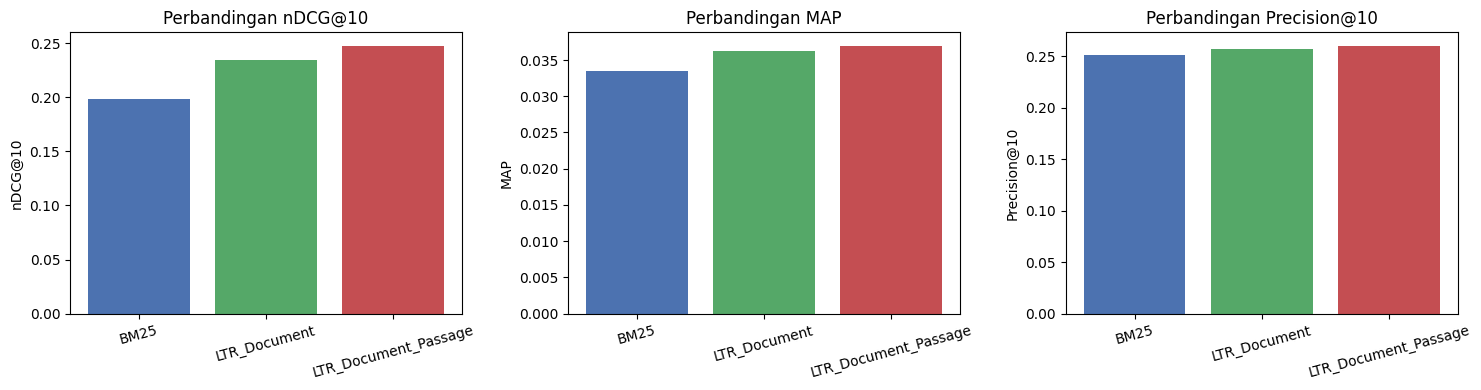

In [9]:
gkf = GroupKFold(n_splits=N_SPLITS)
groups = data["topic_id"].values
X_dummy = np.zeros(len(data))

all_predictions = []
feature_importances = []

for fold, (train_idx, test_idx) in enumerate(gkf.split(X_dummy, data["judgment"], groups), start=1):
    train_data = data.iloc[train_idx].copy()
    test_data = data.iloc[test_idx].copy()
    test_topics = sorted(test_data["topic_id"].unique().tolist())

    # 1. SISTEM 1: BASELINE BM25
    baseline = test_data[["topic_id", "cord_uid", "bm25_score"]].rename(columns={"bm25_score": "predicted_score"})
    baseline["system"] = "BM25"
    baseline["fold"] = fold
    all_predictions.append(baseline)

    # 2. SISTEM 2: LTR DOCUMENT
    model_doc = train_lambdamart(train_data, SYSTEM2_FEATURES)
    res_doc = test_data[["topic_id", "cord_uid"]].copy()
    res_doc["predicted_score"] = model_doc.predict(test_data[SYSTEM2_FEATURES])
    res_doc["system"] = "LTR_Document"
    res_doc["fold"] = fold
    all_predictions.append(res_doc)

    # 3. SISTEM 3: LTR DOCUMENT + PASSAGE
    model_passage = train_lambdamart(train_data, SYSTEM3_FEATURES)
    res_passage = test_data[["topic_id", "cord_uid"]].copy()
    res_passage["predicted_score"] = model_passage.predict(test_data[SYSTEM3_FEATURES])
    res_passage["system"] = "LTR_Document_Passage"
    res_passage["fold"] = fold
    all_predictions.append(res_passage)

    feature_importances.append(pd.DataFrame({
        "feature": SYSTEM3_FEATURES,
        "importance": model_passage.feature_importances_,
        "fold": fold
    }))
    print(f"Fold {fold} selesai (Topik uji: {test_topics})")
    gc.collect()

predictions_df = pd.concat(all_predictions, ignore_index=True)
importance_df = pd.concat(feature_importances, ignore_index=True)

# Evaluasi seluruh 35 topik
systems = ["BM25", "LTR_Document", "LTR_Document_Passage"]
metrics = ["nDCG@10", "MAP", "Precision@10", "Recall@100"]

all_metrics = []
for system in systems:
    sys_preds = predictions_df[predictions_df["system"] == system]
    for topic_id in sorted(sys_preds["topic_id"].unique()):
        topic_preds = sys_preds[sys_preds["topic_id"] == topic_id]
        res = evaluate_ranking(topic_id, topic_preds, qrels)
        res["system"] = system
        res["fold"] = int(topic_preds["fold"].iloc[0])
        all_metrics.append(res)

results = pd.DataFrame(all_metrics)

# 1. Statistik Deskriptif Metrik Evaluasi Tiap Sistem (35 Topik)
print("\n=== STATISTIK DESKRIPTIF METRIK EVALUASI TIAP SISTEM (35 TOPIK) ===")
desc_rows = []
for system in systems:
    print(f"\n--- Sistem: {system} ---")
    sys_desc = results[results["system"] == system][metrics].describe().round(4)
    print(sys_desc.to_string())
    sys_desc_export = sys_desc.reset_index().rename(columns={"index": "Statistik"})
    sys_desc_export.insert(0, "System", system)
    desc_rows.append(sys_desc_export)

desc_all_df = pd.concat(desc_rows, ignore_index=True)

# 2. Rata-Rata Performa Ketiga Sistem
summary = results.groupby("system", sort=False)[metrics].mean().reset_index()
print("\n=== RATA-RATA PERFORMA KETIGA SISTEM (35 TOPIK) ===")
print(summary.round(4).to_string(index=False))

# 3. Uji Signifikansi Wilcoxon
print("\n=== UJI SIGNIFIKANSI WILCOXON (p-value) ===")
wilcoxon_rows = []
for sys_a, sys_b in [("BM25", "LTR_Document"), ("BM25", "LTR_Document_Passage"), ("LTR_Document", "LTR_Document_Passage")]:
    df_a = results[results["system"] == sys_a].sort_values("topic_id")
    df_b = results[results["system"] == sys_b].sort_values("topic_id")
    row_res = {"Perbandingan": f"{sys_a} vs {sys_b}"}
    for m in ["nDCG@10", "MAP", "Precision@10"]:
        _, p_val = wilcoxon(df_a[m].values, df_b[m].values)
        row_res[f"{m} (p-val)"] = round(p_val, 4)
    wilcoxon_rows.append(row_res)

wilcoxon_df = pd.DataFrame(wilcoxon_rows)
print(wilcoxon_df.to_string(index=False))

# 4. Feature Importance
print("\n=== RATA-RATA FEATURE IMPORTANCE (LTR_Document_Passage) ===")
fi_summary = importance_df.groupby("feature")["importance"].mean().sort_values(ascending=False).reset_index()
print(fi_summary.round(4).to_string(index=False))

# Simpan seluruh hasil evaluasi ke CSV
desc_all_df.to_csv("statistik_deskriptif_tiap_sistem.csv", index=False)
summary.round(4).to_csv("rata_rata_performa_3_sistem.csv", index=False)
wilcoxon_df.to_csv("hasil_uji_wilcoxon.csv", index=False)
fi_summary.round(4).to_csv("feature_importance_ltr_passage.csv", index=False)
results.to_csv("hasil_metrik_per_topik.csv", index=False)

# 5. Visualisasi
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for idx, metric in enumerate(["nDCG@10", "MAP", "Precision@10"]):
    axes[idx].bar(summary["system"], summary[metric], color=["#4C72B0", "#55A868", "#C44E52"])
    axes[idx].set_title(f"Perbandingan {metric}")
    axes[idx].set_ylabel(metric)
    axes[idx].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig("perbandingan_performa_3_sistem.png", dpi=300, bbox_inches="tight")
plt.show()

# Interpretasi Hasil 3 sistem


* Konsistensi Re-Ranking Tervalidasi (Recall@100 = 0.1169): Nilai Recall@100 kini identik di ketiga sistem (dan meningkat dibanding percobaan awal 0.1057 berkat perluasan kueri query + question). Ini membuktikan bahwa peningkatan skor murni berasal dari kemampuan re-ranking model LambdaMART, bukan karena perbedaan pool kandidat.
* Keunggulan Model LTR & Kontribusi Fitur Passage:
  * Sistem 2 (LTR_Document) menaikkan kualitas urutan 10 teratas (nDCG@10) sebesar +18,16% dari 0.1982 ke 0.2342 berkat normalisasi fitur per topik dan rasio judul.
  * Sistem 3 (LTR_Document_Passage) meraih performa terbaik di seluruh metrik, mendongkrak nDCG@10 sebesar +24,92% di atas BM25 (0.2476 vs 0.1982) dan +5,72% di atas LTR_Document (0.2476 vs 0.2342). Ini membuktikan bahwa fitur segmen mikro (passage) membantu mengangkat dokumen relevan yang memiliki kepadatan jawaban di bagian tertentu abstrak. 

# Interpretasi Uji Signifikansi Wilcoxon (𝑝-value)

* BM25 vs LTR_Document: Peningkatan pada metrik MAP terbukti signifikan secara statistik (𝑝 = 0.0275 < 0.05). Ini menunjukkan bahwa LTR_Document secara konsisten menempatkan dokumen-dokumen relevan lebih tinggi di keseluruhan daftar peringkat dibandingkan BM25.
* BM25 vs LTR_Document_Passage: Peningkatan besar pada nDCG@10 (+24,92%, 𝑝 = 0.0754) dan MAP (+10,45%, 𝑝 = 0.0674) menunjukkan signifikansi marginal (𝑝 < 0.10, sangat mendekati ambang batas 0.05 untuk ukuran sampel 35 topik). Artinya, rata-rata skornya naik tajam, namun terdapat variasi performa antar-topik sehingga belum menembus 𝑝 < 0.05 pada uji non-parametrik 35 kueri.
* LTR_Document vs LTR_Document_Passage: Perbedaan antara kedua model LTR tidak signifikan secara statistik (𝑝 > 0.60), meskipun secara rata-rata penambahan fitur passage memberikan tambahan skor nDCG@10 sebesar +0.0134.

# Kesimpulan

1. Perluasan kueri (full_query) dan normalisasi fitur per topik berhasil mengatasi masalah overfitting pada percobaan awal, membuat kedua model Learning to Rank mengungguli baseline BM25 di seluruh metrik.
2. Penambahan fitur passage memberikan nilai nDCG@10 tertinggi (0.2476), membuktikan bahwa sinyal relevansi tingkat paragraf (passage-level) melengkapi fitur tingkat dokumen untuk pencarian literatur biomedis.
3. Secara statistik, perbaikan peringkat menyeluruh (MAP) dari baseline BM25 ke model LTR terbukti signifikan (𝑝 = 0.0275), sedangkan peningkatan pada LTR_Document_Passage bersifat marginally significant (𝑝 = 0.0754) akibat keterbatasan jumlah topik evaluasi (35 topik) pada dataset TREC-COVID.